# 03 · Results analysis

This notebook turns the saved runs into the **tables and figures of the paper**: mean ± sd per arm and budget, a significance test for every contrast, and the plots. It only reads the result folders; it does not train anything and needs no GPU. The code lives in `src/gainsplit/analysis.py`.

**Where it runs.** Locally (from the repo) or on Kaggle. On Kaggle add the results as inputs and set the folders in step 2. Scores in the tables are in percentage points (macro-F1 0.882 is shown as 88.2).

## 1. Get the code
Makes the `gainsplit` package importable. Locally it uses the `src/` folder of this repo; on Kaggle it fetches the repo from GitHub. Without this step the later cells cannot find the analysis functions.

In [34]:
import os, subprocess, sys
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle")
if ON_KAGGLE:
    REPO_DIR = "/tmp/GainSplit"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Ariffurrhmn/GainSplit.git", REPO_DIR], check=True)
else:
    REPO_DIR = str(Path.cwd().parent) if Path.cwd().name == "experiments" else str(Path.cwd())
sys.path.insert(0, f"{REPO_DIR}/src")

import pandas as pd
from gainsplit import analysis as an
pd.set_option("display.width", 200)

## 2. Choose the result folders
Lists the folders that contain a `runs/` subfolder (Pass 1, Pass 2a, Pass 2b, Pass 3). All of them are pooled into one table. If the same arm, budget, seed and tag appears twice, the last folder in the list wins and a warning is printed. Edit this list when new passes finish. On Kaggle too, the folders come from the GitHub clone, because every finished pass is committed to the repo; no Kaggle dataset is needed.

In [35]:
if ON_KAGGLE:
    # the results are committed to the repo, so the clone from step 1 already has them
    RESULTS_DIRS = [f"{REPO_DIR}/results/pass1", f"{REPO_DIR}/results/pass2a", f"{REPO_DIR}/results/pass2b", f"{REPO_DIR}/results/pass3"]
    OUT_DIR = "/kaggle/working/analysis"
else:
    RESULTS_DIRS = [f"{REPO_DIR}/results/pass1", f"{REPO_DIR}/results/pass2a", f"{REPO_DIR}/results/pass2b", f"{REPO_DIR}/results/pass3"]
    OUT_DIR = f"{REPO_DIR}/results/analysis"

N_BOOT = 10000     # bootstrap resamples
RNG_SEED = 0       # fixed so the numbers are reproducible

## 3. Load every run
Reads each `result.json` and notes where its prediction files are. One row per run (arm, budget, seed, scores). The count table shows how many seeds each arm has at each budget: it should be 5 everywhere a run was planned. A gap here means a missing run, so check it before trusting any number below. Runs with a tag (the Pass 3 variants) are loaded too but kept out of the main tables.

In [36]:
runs = an.load_runs(*RESULTS_DIRS)
print(len(runs), "runs,", int((runs["tag"] != "").sum()), "of them with a tag (Pass 3 variants)")
# the main tables and contrasts below use the untagged runs only
an.untagged(runs).groupby(["arm", "budget"]).size().unstack(fill_value=0)

150 runs


budget,1,5,10,30,100
arm,,,,,
A0,5,5,5,5,5
A1,5,5,5,5,5
A2,5,0,5,0,0
A3,5,5,5,5,0
A4,5,5,5,5,0
A5,5,5,5,5,0
A6,5,0,5,0,0
A7,5,0,5,0,0
A8,5,0,5,0,0


## 4. Mean ± sd table
For each arm and budget: the mean test macro-F1 over the seeds and the standard deviation across seeds. This is the main results table. The sd shows how much a single run moves around because of the seed (which labeled items were drawn, initialisation).

In [37]:
summ = an.summary_table(runs, split="test", metric="macro_f1")
wide = an.summary_wide(summ)
an.save_table(summ, OUT_DIR, "summary_test_macro_f1_long")
an.save_table(wide, OUT_DIR, "summary_test_macro_f1")
wide

,arm,1%,5%,10%,30%,100%
0,A0,69.71 ± 0.68,75.34 ± 0.63,78.14 ± 0.63,81.07 ± 0.37,84.66 ± 0.00
1,A1,80.42 ± 1.24,86.61 ± 0.54,88.21 ± 0.31,90.85 ± 0.21,93.33 ± 0.38
2,A2,82.05 ± 0.64,NaN,88.43 ± 0.41,NaN,NaN
3,A3,80.29 ± 1.84,86.83 ± 0.71,88.64 ± 0.51,91.09 ± 0.43,NaN
4,A4,80.52 ± 1.59,86.51 ± 1.00,88.09 ± 0.40,90.30 ± 0.23,NaN
5,A5,78.12 ± 2.74,86.62 ± 0.53,88.44 ± 0.32,90.77 ± 0.18,NaN
6,A6,82.04 ± 0.75,NaN,88.81 ± 0.30,NaN,NaN
7,A7,82.00 ± 0.61,NaN,89.76 ± 0.15,NaN,NaN
8,A8,80.03 ± 1.66,NaN,88.06 ± 0.28,NaN,NaN


## 5. Same table on the dev set
The dev set was used for choices such as the learning rate. Showing it next to the test table lets you check that the picture is the same and nothing was tuned on the test set.

In [38]:
summ_dev = an.summary_table(runs, split="dev", metric="macro_f1")
an.save_table(summ_dev, OUT_DIR, "summary_dev_macro_f1_long")
an.save_table(an.summary_wide(summ_dev), OUT_DIR, "summary_dev_macro_f1")
an.summary_wide(summ_dev)

,arm,1%,5%,10%,30%,100%
0,A0,69.80 ± 1.05,75.28 ± 0.60,77.79 ± 0.82,81.50 ± 0.56,85.05 ± 0.00
1,A1,79.31 ± 1.30,85.06 ± 0.56,87.03 ± 0.59,90.00 ± 0.38,92.81 ± 0.27
2,A2,80.64 ± 0.71,NaN,87.22 ± 0.37,NaN,NaN
3,A3,78.87 ± 1.80,84.98 ± 0.78,87.18 ± 0.48,89.92 ± 0.33,NaN
4,A4,79.32 ± 1.62,84.47 ± 0.69,86.86 ± 0.62,89.10 ± 0.56,NaN
5,A5,76.82 ± 2.60,85.13 ± 0.67,87.08 ± 0.44,89.59 ± 0.44,NaN
6,A6,81.06 ± 1.16,NaN,87.77 ± 0.48,NaN,NaN
7,A7,81.15 ± 0.94,NaN,88.32 ± 0.32,NaN,NaN
8,A8,78.73 ± 1.45,NaN,86.95 ± 0.52,NaN,NaN


## 6. Significance of each contrast (paired bootstrap)
The differences between arms are small (a few tenths of a point), so comparing seed means is too noisy. Instead we use the fact that **every arm is scored on the same test headlines**. We draw 10,000 resamples of the test headlines (with replacement). In each resample, every seed of both arms is scored on the *same* resampled headlines, the macro-F1 difference is computed per seed, and then averaged over seeds. The spread of these 10,000 averages gives a 95% interval; the p-value is twice the smaller share of resamples with a difference ≤ 0 or ≥ 0. A contrast is clearly different from zero when its interval excludes 0. Only seeds that both arms have are used (`n_seeds`).

Contrasts: the Pass 1 ones (A3−A1, A4−A1, A5−A1, A5−A3, A5−A4), the Pass 2 ones, and the interaction A5−A4−A3+A1 (is GAN + helpers more or less than the two effects added together?). Contrasts with a missing arm are skipped. All contrasts are reported with no multiple-testing correction, which the paper states.

In [39]:
contrasts = an.contrast_table(runs, split="test", metric="macro_f1", n=N_BOOT, rng_seed=RNG_SEED)
an.save_table(contrasts, OUT_DIR, "contrasts_test_macro_f1")
contrasts.round({"mean_diff": 2, "ci_low": 2, "ci_high": 2, "p": 4})

,contrast,budget,mean_diff,ci_low,ci_high,p,n_seeds
0,A3-A1,1,-0.13,-0.70,0.45,0.6538,5
1,A3-A1,5,0.21,-0.23,0.66,0.3506,5
2,A3-A1,10,0.42,-0.00,0.85,0.0506,5
3,A3-A1,30,0.24,-0.15,0.64,0.2236,5
4,A4-A1,1,0.10,-0.51,0.70,0.7486,5
5,A4-A1,5,-0.11,-0.54,0.32,0.6224,5
6,A4-A1,10,-0.13,-0.58,0.32,0.5738,5
7,A4-A1,30,-0.55,-0.94,-0.16,0.0066,5
8,A5-A1,1,-2.30,-2.99,-1.63,0.0000,5
9,A5-A1,5,0.00,-0.45,0.46,0.9894,5


## 7. One contrast in detail
Runs a single comparison by hand so you can see the output: `mean_diff` is the difference on the full test set, `boot_mean` the average over resamples, `ci_low`/`ci_high` the 95% interval, `p` the two-sided p-value. Change the arms and budget to inspect any other pair. Differences here are in plain macro-F1 (0.004 = 0.4 points).

In [40]:
an.paired_bootstrap(runs, "A5", "A4", budget=10, split="test", metric="macro_f1", n=N_BOOT, rng_seed=RNG_SEED)

{'mean_diff': 0.0035870208912618827,
 'boot_mean': 0.0036245838429773726,
 'ci_low': -0.0008290257878581786,
 'ci_high': 0.008116827968003443,
 'p': 0.1146,
 'n_seeds': 5}

## 8. Figure: score against label budget
One line per arm: mean test macro-F1 against the share of labeled data (log axis), with error bars of one sd over seeds. It shows where the arms differ most (expected at small budgets) and where they converge.

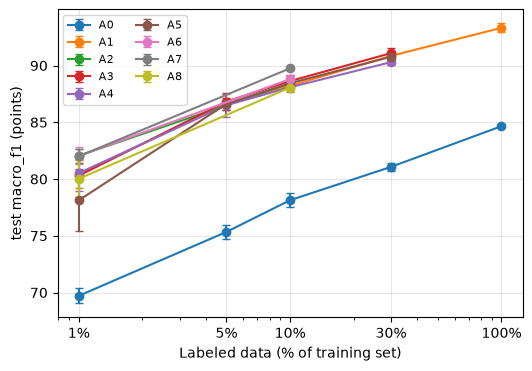

In [41]:
fig = an.plot_f1_vs_budget(runs, OUT_DIR, split="test", metric="macro_f1")

## 9. Figure: GAN training curves
For the two GAN arms (A4, A5), the discriminator's probability of calling a text "fake", for real texts and for generated ones, over the training steps (mean over seeds, band = min to max). If the generated line stays far above the real line the discriminator wins easily; if the two meet, the generator is fooling it. This is evidence for *why* the GAN part does or does not help.

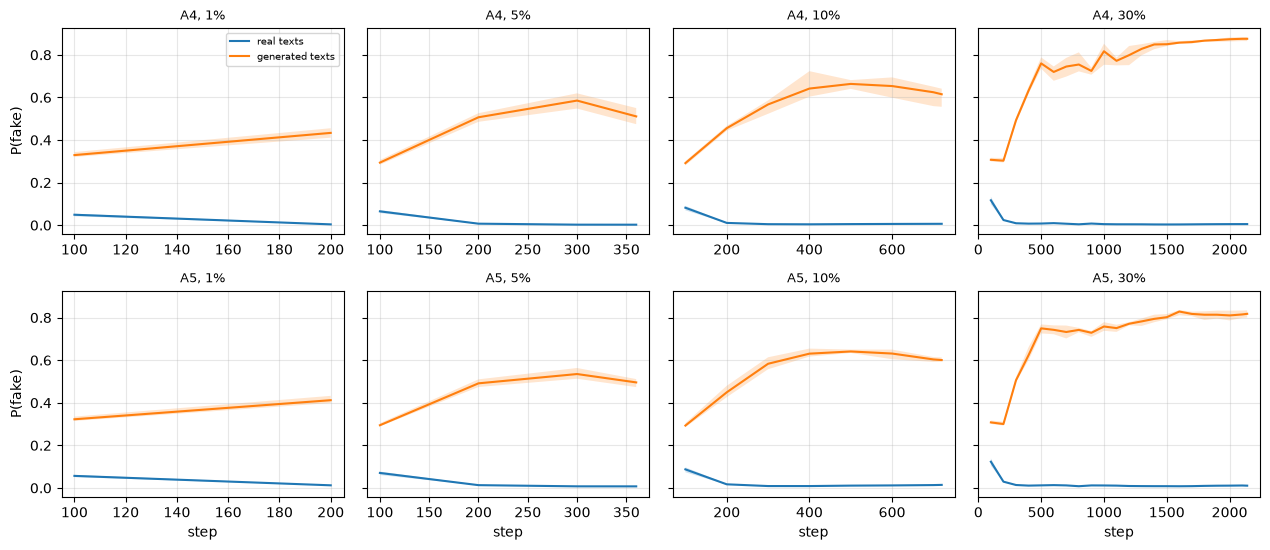

In [42]:
fig = an.plot_gan_curves(runs, OUT_DIR)

## 10. iSarcasmEval table
The same models scored on a different sarcasm dataset (iSarcasmEval test, no retraining): macro-F1, F1 of the sarcastic class (that benchmark's official metric) and ROC-AUC, mean ± sd over seeds. It checks whether anything carries over outside news headlines.

In [43]:
isarc = an.isarc_table(runs)
an.save_table(isarc, OUT_DIR, "isarc_test")
isarc

,arm,budget,n_seeds,macro_f1,f1_sarcastic,roc_auc
0,A0,1,5,45.46 ± 0.65,12.18 ± 1.55,43.87 ± 1.34
1,A0,5,5,46.30 ± 0.60,13.39 ± 1.47,45.66 ± 2.04
2,A0,10,5,46.01 ± 0.59,12.50 ± 0.85,45.30 ± 0.79
3,A0,30,5,46.43 ± 0.35,13.50 ± 0.64,44.97 ± 0.63
4,A0,100,5,45.89 ± 0.00,12.14 ± 0.00,44.57 ± 0.00
5,A1,1,5,47.67 ± 2.27,17.68 ± 2.96,50.20 ± 2.44
6,A1,5,5,49.05 ± 1.09,17.25 ± 4.87,51.03 ± 3.14
7,A1,10,5,50.20 ± 1.29,17.55 ± 3.90,50.96 ± 2.19
8,A1,30,5,49.98 ± 1.32,16.53 ± 2.89,49.99 ± 2.45
9,A1,100,5,50.96 ± 0.80,17.19 ± 1.82,51.66 ± 2.19


# Pass 3: what drives the gain?
Everything below uses the tagged Pass 3 runs (helper-label variants, shuffled helper labels, masked test sets, training on iSarcasmEval) and the helper labels themselves. These parts answer the paper's follow-up questions: does the gain depend on label quality (RQ2), does it carry over to another dataset (RQ3), and does the model lean on outlet-specific words? If no tagged run is loaded (Pass 3 not finished or not in `RESULTS_DIRS`), the run-based cells below print a message and stop; the label-only cells need the files in `data/processed/` and are skipped when they are missing (on Kaggle the data folder is not in the clone).

## 12. Pass 3 set-up
Defines where the helper-label files and the gold audit live and checks that tagged runs were loaded. `HAS_P3` is the switch used by the run-based cells.

In [ ]:
from IPython.display import display

PROCESSED_DIR = f"{REPO_DIR}/data/processed"
GOLD_PATH = f"{REPO_DIR}/results/gold_audit/gold_sentiment_audit.csv"
HAS_P3 = bool((runs["tag"] != "").any())
NO_P3 = "No tagged runs loaded: add results/pass3 to RESULTS_DIRS (step 2) once Pass 3 has finished. Skipping this cell."
if HAS_P3:
    print(runs[runs["tag"] != ""].groupby(["tag", "arm", "budget"]).size().rename("n_seeds").to_string())
else:
    print(NO_P3)

## 13. Check: mask re-runs equal the originals
The `mask` runs repeat A1, A3, A4, A6 and A7 at 10% only to add the masked test sets. Training is deterministic, so their normal test macro-F1 and test probabilities must equal the original untagged runs (tolerance 1e-6). If any row is flagged, the masked numbers are not comparable with the main tables and must not be used until the cause is found.

In [ ]:
if not (runs["tag"] == "mask").any():
    print("No tag == 'mask' runs loaded. Skipping this cell.")
else:
    mask_check = an.check_mask_reruns(runs)
    an.save_table(mask_check, OUT_DIR, "mask_rerun_check", default_decimals=8)
    print("max |macro-F1 difference|:", mask_check["f1_diff"].max(), "| max |probability difference|:", mask_check["pred_diff"].max())
    print("ALL MATCH" if mask_check["ok"].all() else "MISMATCH: see the rows with ok == False")
    display(mask_check[~mask_check["ok"]] if not mask_check["ok"].all() else mask_check.head())

## 14. Masked test sets: do the models lean on outlet cues?
Test headlines are scored again after replacing the 200 most outlet-indicative words (`cuemask`) or the same number of random words (`randmask`) with [MASK]. `drop_cue` = test − cuemask and `drop_rand` = test − randmask are the losses in macro-F1 (points). **shortcut_gap = drop_cue − drop_rand** is the extra loss caused by the cue words in particular: random masking is the control for "any masking hurts". A gap clearly above 0 (interval excludes 0) means the model relies on outlet-specific vocabulary rather than on sarcasm. The intervals come from the same paired bootstrap over test items as the contrasts (one resample shared by all seeds).

In [ ]:
if not HAS_P3:
    print(NO_P3)
else:
    masked = an.masked_table(runs, n=N_BOOT, rng_seed=RNG_SEED)
    if masked.empty:
        print("No run has the masked splits. Skipping this cell.")
    else:
        an.save_table(masked, OUT_DIR, "masked_test_macro_f1")
        display(masked.round(2))

## 15. Label quality (RQ2)
Each variant of the helper labels (soft targets, 25% / 50% flipped labels, VADER, a second teacher, sentiment only, emotion only) is compared with the normal run of the same arm: A3 at 10% and A2 at 1%. The last two rows use A2 with **shuffled** helper labels (A9): if shuffled labels do as well as the real ones, the gain does not come from what the helpers say, and the comparison with A1 shows whether extra heads help at all. Same paired bootstrap as step 6 (difference in test macro-F1, in points; interval excludes 0 = clear effect).

In [ ]:
if not HAS_P3:
    print(NO_P3)
else:
    label_q = an.label_quality_table(runs, split="test", metric="macro_f1", n=N_BOOT, rng_seed=RNG_SEED)
    if label_q.empty:
        print("None of the label-quality variants is loaded yet. Skipping this cell.")
    else:
        an.save_table(label_q, OUT_DIR, "label_quality_contrasts")
        display(label_q.round({"mean_diff": 2, "ci_low": 2, "ci_high": 2, "p": 4}))

## 16. Transfer to iSarcasmEval (RQ3)
For every arm, budget and tag: ROC-AUC on the iSarcasmEval test set (points, 50 = chance) with a bootstrap 95% interval (resample the test items; the same resample is applied to every seed, then the AUC is averaged over seeds). `excludes_50` says whether the interval is entirely above or below chance, i.e. whether anything carries over from news headlines. The runs trained on iSarcasmEval itself (`isarctrain`) are the in-domain reference: the ceiling that the headline-trained models are compared with.

In [ ]:
if not HAS_P3:
    print(NO_P3)
else:
    transfer = an.transfer_table(runs, n=N_BOOT, rng_seed=RNG_SEED)
    an.save_table(transfer, OUT_DIR, "transfer_isarc_auc")
    display(transfer.round(2))

## 17. Do the helper labels predict sarcasm by themselves?
On the training set, how strongly the teacher's sentiment and emotion labels are tied to the sarcasm label: normalised mutual information (0 = independent, 1 = identical) and Cramér's V, plus a probe, a logistic regression on the 8 teacher probabilities predicting sarcasm with 5-fold cross-validated ROC-AUC. If the association is large, helper heads could help simply because the labels leak the target; if the probe is near 0.5, any gain must come from elsewhere. CPU only, no runs needed.

In [ ]:
from pathlib import Path
_h, _t = Path(PROCESSED_DIR) / "helper_labels.csv", Path(PROCESSED_DIR) / "headlines_train.csv"
if not (_h.exists() and _t.exists()):
    print(f"{_h} or {_t} not found (the data folder is not in the repo clone). Skipping this cell.")
else:
    helper_df, train_df = pd.read_csv(_h), pd.read_csv(_t)
    helper_assoc = an.helper_shortcut_table(helper_df, train_df)
    an.save_table(helper_assoc, OUT_DIR, "helper_vs_sarcasm", default_decimals=3)
    display(helper_assoc.round(3))

## 18. Teacher sentiment against the owner's gold labels
The 200 audited training headlines have a sentiment label from the owner (`gold_sentiment`). For every sentiment source available (the main teacher `sent_label`, and `vader_label` and `teacher2_label` if `helper_sent_alt.csv` exists) the table gives accuracy, macro-F1 and Cohen's kappa against the gold label, on all 200 and on the confident ones only (`unsure == 0`). It tells how noisy each teacher's labels are, which is the reference for reading the label-quality contrasts in step 15.

In [ ]:
_gold, _notes = an.load_gold(PROCESSED_DIR, GOLD_PATH, train=train_df if "train_df" in globals() else None)
for _n in _notes:
    print("note:", _n)
if _gold is None:
    print("Skipping this cell.")
else:
    gold_tab = an.gold_table(_gold)
    an.save_table(gold_tab, OUT_DIR, "gold_sentiment_agreement", default_decimals=2, decimals={"kappa": 3})
    display(gold_tab.round({"accuracy": 2, "macro_f1": 2, "kappa": 3}))

## 19. Gold against teacher: which one predicts sarcasm?
On the same 200 headlines: the association with the sarcasm label for the owner's sentiment and for the teacher's, and a cross-validated AUC from the one-hot sentiment label alone. The last row is the AUC difference (gold − teacher) with a permutation p-value (each headline randomly swaps which label is called gold, 500 times). If the teacher is no more tied to sarcasm than the owner's careful labels, the teacher is not injecting a sarcasm shortcut. With only 200 items the test is weak, so read it as a sanity check.

In [ ]:
if _gold is None or "label" not in _gold or _gold["label"].isna().all():
    print("Needs the gold audit, helper_labels.csv and headlines_train.csv. Skipping this cell.")
else:
    gold_assoc = an.gold_shortcut_table(_gold, n_perm=500, seed=RNG_SEED)
    an.save_table(gold_assoc, OUT_DIR, "gold_vs_teacher_sarcasm", default_decimals=3, decimals={"p_perm": 3})
    display(gold_assoc.round(3))

## 20. Where the files went
Lists everything written to the output folder (CSV and Markdown tables, PDF and PNG figures). On Kaggle the folder is also zipped to `results_analysis.zip`: download it from the Output tab.

In [44]:
if ON_KAGGLE:
    import shutil
    shutil.make_archive("/kaggle/working/results_analysis", "zip", OUT_DIR)
    print("zipped to /kaggle/working/results_analysis.zip")
sorted(p.name for p in Path(OUT_DIR).iterdir())

['contrasts_test_macro_f1.csv',
 'contrasts_test_macro_f1.md',
 'fig_f1_vs_budget.pdf',
 'fig_f1_vs_budget.png',
 'fig_gan_curves.pdf',
 'fig_gan_curves.png',
 'isarc_test.csv',
 'isarc_test.md',
 'summary_dev_macro_f1.csv',
 'summary_dev_macro_f1.md',
 'summary_dev_macro_f1_long.csv',
 'summary_dev_macro_f1_long.md',
 'summary_test_macro_f1.csv',
 'summary_test_macro_f1.md',
 'summary_test_macro_f1_long.csv',
 'summary_test_macro_f1_long.md']